# 02 · Modelo final: TF-IDF + Linear SVM, ajuste de umbrales y matrices de confusión

**InterviewIQ · AD5018 · UTEC 2026-2**

1. Entrena TF-IDF + Linear SVM calibrado (misma configuración que los `.pkl` de `models/`).
2. Lo compara con el baseline TF-IDF + Logistic Regression.
3. Ajusta el umbral de cada componente en validación.
4. Evalúa en prueba con los umbrales que usa la app y dibuja las matrices de confusión S/T/A/R.
5. Lee los errores en costos de negocio (falso positivo vs falso negativo).

## 1. Datos y split

In [1]:
import re, json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEMILLA = 42
ETIQUETAS = ["situacion", "tarea", "accion", "resultado"]

def limpiar(t):
    # Misma limpieza que usa app.py antes de predecir
    t = str(t).lower()
    t = re.sub(r"[^\w\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df = pd.read_csv(RAIZ / "data/raw/interviewiq_star_v1.csv")
df["texto"] = df["respuesta"].map(limpiar)

# Split 70 / 10 / 20 (entrenamiento / validación / prueba)
idx_tmp, idx_test = train_test_split(df.index, test_size=0.20, random_state=SEMILLA)
idx_train, idx_val = train_test_split(idx_tmp, test_size=0.125, random_state=SEMILLA)  # 0.125 * 0.8 = 0.10
train, val, test = df.loc[idx_train], df.loc[idx_val], df.loc[idx_test]
print(f"Total: {len(df)} | train: {len(train)} | val: {len(val)} | test: {len(test)}")
df[ETIQUETAS].mean().rename("% positivos").round(2).to_frame().T

Total: 200 | train: 140 | val: 20 | test: 40


,situacion,tarea,accion,resultado
% positivos,0.66,0.55,0.68,0.38


## 2. Modelos

El SVM es idéntico al de `models/clasificador_star_*.pkl`: `LinearSVC(class_weight='balanced')` dentro de `CalibratedClassifierCV(cv=3, method='sigmoid')` para obtener probabilidades.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score, confusion_matrix

def tfidf():
    return TfidfVectorizer(max_features=5000, min_df=2, ngram_range=(1, 2), sublinear_tf=True)

def pipeline_lr():
    return Pipeline([("tfidf", tfidf()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEMILLA))])

def pipeline_svm():
    svc = LinearSVC(class_weight="balanced", max_iter=2000, random_state=SEMILLA)
    return Pipeline([("tfidf", tfidf()),
                     ("clf", CalibratedClassifierCV(estimator=svc, cv=3, method="sigmoid"))])

modelos = {"LR": {}, "SVM": {}}
proba = {"LR": {}, "SVM": {}}
for et in ETIQUETAS:
    for nombre, fabrica in [("LR", pipeline_lr), ("SVM", pipeline_svm)]:
        m = fabrica().fit(train["texto"], train[et])
        modelos[nombre][et] = m
        proba[nombre][et] = {"val": m.predict_proba(val["texto"])[:, 1],
                             "test": m.predict_proba(test["texto"])[:, 1]}
print("Modelos entrenados")

Modelos entrenados


## 3. Baseline vs modelo final

### 3a. Validación cruzada repetida (comparación principal)

Con solo 40 respuestas de prueba, un único split es muy ruidoso: un error cambia el F1 varios puntos. Por eso la comparación principal usa validación cruzada estratificada 5-fold repetida 5 veces (25 evaluaciones por modelo) sobre las 200 respuestas, con umbral 0.5.

In [3]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEMILLA)
filas = []
for et in ETIQUETAS:
    f_lr = cross_val_score(pipeline_lr(), df["texto"], df[et], cv=cv, scoring="f1_macro")
    f_svm = cross_val_score(pipeline_svm(), df["texto"], df[et], cv=cv, scoring="f1_macro")
    dif = f_svm.mean() - f_lr.mean()
    filas.append({"componente": et,
                  "F1 LR (media)": f_lr.mean(), "± LR": f_lr.std(),
                  "F1 SVM (media)": f_svm.mean(), "± SVM": f_svm.std(),
                  "ganador": "SVM" if dif > 0.005 else ("LR" if dif < -0.005 else "Empate")})
comp_cv = pd.DataFrame(filas).set_index("componente")
comp_cv.loc["PROMEDIO", ["F1 LR (media)", "F1 SVM (media)"]] = comp_cv[["F1 LR (media)", "F1 SVM (media)"]].mean()
comp_cv.loc["PROMEDIO", "ganador"] = "SVM" if comp_cv.loc["PROMEDIO", "F1 SVM (media)"] > comp_cv.loc["PROMEDIO", "F1 LR (media)"] else "LR"
comp_cv.round(3)

,F1 LR (media),± LR,F1 SVM (media),± SVM,ganador
componente,,,,,
situacion,0.929,0.044,0.934,0.042,SVM
tarea,0.848,0.047,0.848,0.055,Empate
accion,0.815,0.062,0.829,0.058,SVM
resultado,0.779,0.041,0.793,0.045,SVM
PROMEDIO,0.843,NaN,0.851,NaN,SVM


El SVM iguala o supera al baseline en los 4 componentes, pero la diferencia es pequeña y queda dentro de la desviación estándar. Se elige el SVM por ser consistentemente igual o mejor, sabiendo que con 200 ejemplos los dos modelos rinden de forma parecida.

### 3b. Mismo split de prueba (umbral fijo 0.5)

In [4]:
filas = []
for et in ETIQUETAS:
    f = {"componente": et}
    for nombre in ["LR", "SVM"]:
        pred = (proba[nombre][et]["test"] >= 0.5).astype(int)
        f[f"F1 {nombre}"] = f1_score(test[et], pred, average="macro")
    f["ganador"] = "SVM" if f["F1 SVM"] > f["F1 LR"] + 1e-9 else ("Empate" if abs(f["F1 SVM"] - f["F1 LR"]) < 1e-9 else "LR")
    filas.append(f)
comp = pd.DataFrame(filas).set_index("componente")
comp.loc["PROMEDIO", ["F1 LR", "F1 SVM"]] = comp[["F1 LR", "F1 SVM"]].mean()
comp.loc["PROMEDIO", "ganador"] = "SVM" if comp.loc["PROMEDIO", "F1 SVM"] > comp.loc["PROMEDIO", "F1 LR"] else "LR"
comp.round(3)

,F1 LR,F1 SVM,ganador
componente,,,
situacion,0.971,0.971,Empate
tarea,0.893,0.893,Empate
accion,0.796,0.804,SVM
resultado,0.824,0.768,LR
PROMEDIO,0.871,0.859,LR


## 4. Ajuste de umbrales en validación

Para cada componente se prueba el umbral de 0.05 a 0.95 y se elige el que maximiza

`score = F1 macro − 0.5 × tasa_FP`, con `tasa_FP = FP / (FP + TN)`.

Se castiga el falso positivo porque es el error más caro: decirle al estudiante que un componente está presente cuando no lo está.

⚠️ El set de validación tiene solo 20 respuestas, así que el umbral óptimo es inestable. Por eso la app usa umbrales redondeados y revisados con casos límite (`mvp/evidencia/pruebas_usuario.md`).

In [5]:
def metricas(y, p, u):
    pred = (p >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    tasa_fp = fp / (fp + tn) if (fp + tn) else 0.0
    return {"F1": f1_score(y, pred, average="macro", zero_division=0),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn, "tasa_FP": tasa_fp}

grilla = np.round(np.arange(0.05, 0.96, 0.05), 2)
umbral_optimo = {}
for et in ETIQUETAS:
    p, y = proba["SVM"][et]["val"], val[et].values
    scores = [(metricas(y, p, u)["F1"] - 0.5 * metricas(y, p, u)["tasa_FP"], u) for u in grilla]
    mejor = max(scores)[0]
    # Ante empate se elige el umbral más alto (más conservador frente a falsos positivos)
    umbral_optimo[et] = max(u for s, u in scores if abs(s - mejor) < 1e-9)

UMBRALES_APP = json.load(open(RAIZ / "models/config_clasificador.json"))["umbrales"]
pd.DataFrame({"umbral óptimo (val)": umbral_optimo, "umbral en la app": UMBRALES_APP})

,umbral óptimo (val),umbral en la app
situacion,0.90,0.30
tarea,0.85,0.30
accion,0.20,0.75
resultado,0.65,0.50


## 5. Resultados en prueba con los umbrales de la app

Estos son los números que corresponden a la app desplegada (S 0.30 · T 0.30 · A 0.75 · R 0.50).

In [6]:
def tabla(umbrales):
    filas = []
    for et in ETIQUETAS:
        m = metricas(test[et].values, proba["SVM"][et]["test"], umbrales[et])
        filas.append({"componente": et, "umbral": umbrales[et], "F1 macro": m["F1"],
                      "FP": m["FP"], "FN": m["FN"], "tasa FP": m["tasa_FP"],
                      "cumple ≥ 0.65": "✅" if m["F1"] >= 0.65 else "❌"})
    t = pd.DataFrame(filas).set_index("componente")
    t.loc["PROMEDIO", "F1 macro"] = t["F1 macro"].mean()
    t.loc["PROMEDIO", "cumple ≥ 0.65"] = "✅" if t.loc["PROMEDIO", "F1 macro"] >= 0.65 else "❌"
    return t

res_app = tabla(UMBRALES_APP)
res_app.round(3)

,umbral,F1 macro,FP,FN,tasa FP,cumple ≥ 0.65
componente,,,,,,
situacion,0.30,0.903,3.0,0.0,0.250,✅
tarea,0.30,0.829,6.0,0.0,0.375,✅
accion,0.75,0.733,4.0,6.0,0.286,✅
resultado,0.50,0.768,6.0,3.0,0.240,✅
PROMEDIO,NaN,0.808,NaN,NaN,NaN,✅


In [7]:
print("Con los umbrales óptimos de validación (referencia):")
tabla(umbral_optimo).round(3)

Con los umbrales óptimos de validación (referencia):


,umbral,F1 macro,FP,FN,tasa FP,cumple ≥ 0.65
componente,,,,,,
situacion,0.90,0.943,0.0,2.0,0.000,✅
tarea,0.85,0.670,0.0,13.0,0.000,✅
accion,0.20,0.733,8.0,0.0,0.571,✅
resultado,0.65,0.811,3.0,4.0,0.120,✅
PROMEDIO,NaN,0.789,NaN,NaN,NaN,✅


## 6. Matrices de confusión S/T/A/R (prueba, umbrales de la app)

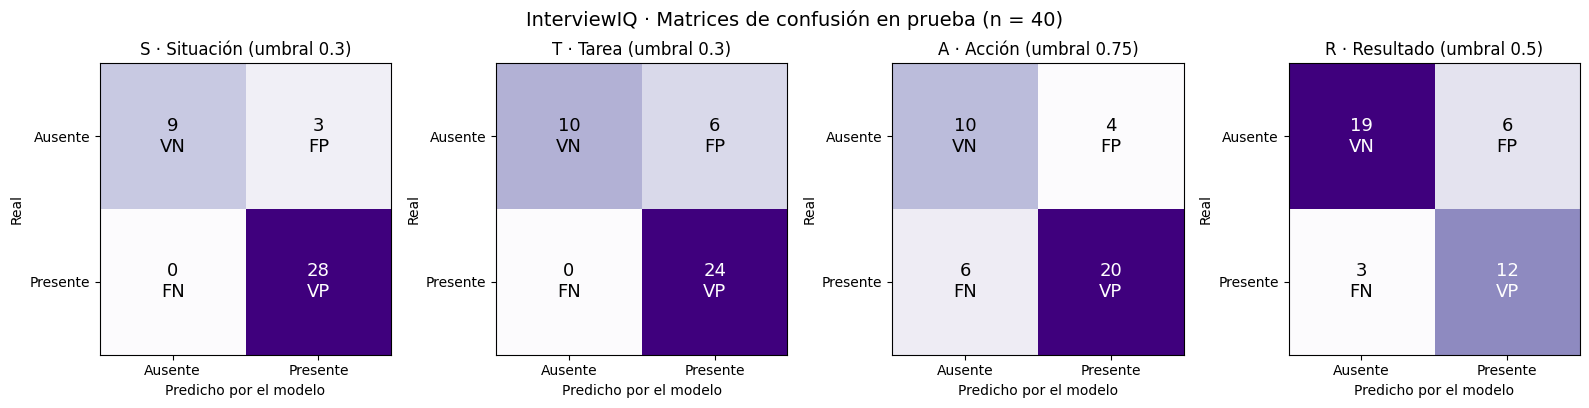

In [8]:
import matplotlib.pyplot as plt

NOMBRES = {"situacion": "S · Situación", "tarea": "T · Tarea", "accion": "A · Acción", "resultado": "R · Resultado"}
fig, ejes = plt.subplots(1, 4, figsize=(16, 4))
for ax, et in zip(ejes, ETIQUETAS):
    pred = (proba["SVM"][et]["test"] >= UMBRALES_APP[et]).astype(int)
    cm = confusion_matrix(test[et], pred, labels=[0, 1])
    ax.imshow(cm, cmap="Purples")
    for i in range(2):
        for j in range(2):
            etiqueta = [["VN", "FP"], ["FN", "VP"]][i][j]
            ax.text(j, i, f"{cm[i, j]}\n{etiqueta}", ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Ausente", "Presente"])
    ax.set_yticks([0, 1], ["Ausente", "Presente"])
    ax.set_xlabel("Predicho por el modelo")
    ax.set_ylabel("Real")
    ax.set_title(f"{NOMBRES[et]} (umbral {UMBRALES_APP[et]})")
fig.suptitle(f"InterviewIQ · Matrices de confusión en prueba (n = {len(test)})", fontsize=14)
fig.tight_layout()
(RAIZ / "notebooks/figuras").mkdir(parents=True, exist_ok=True)
fig.savefig(RAIZ / "notebooks/figuras/matriz_confusion_star.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Lectura en costos de negocio

- **Falso positivo (FP):** la app dice que el componente está y no está. El estudiante no recibe el consejo que necesitaba y cree que su respuesta está completa. **Es el error más caro**: daña el aprendizaje y la confianza.
- **Falso negativo (FN):** la app dice que falta y sí estaba. El estudiante recibe un consejo de más. Es molesto, pero no lo perjudica.

Por eso Acción tiene un umbral alto (0.75): se acepta perder algunos aciertos a cambio de no premiar respuestas sin acción personal (caso límite C2). Situación y Tarea usan umbrales bajos porque casi todas las respuestas las tienen y subir el umbral hacía fallar al modelo con demasiados FN.

In [9]:
costos = res_app.loc[ETIQUETAS, ["umbral", "FP", "FN", "tasa FP"]].copy()
def riesgo(t):
    return "🔴 Alto" if t >= 0.25 else ("🟡 Medio" if t >= 0.10 else "🟢 Bajo")
costos["riesgo por FP"] = costos["tasa FP"].map(riesgo)
costos.round(3)

,umbral,FP,FN,tasa FP,riesgo por FP
componente,,,,,
situacion,0.30,3.0,0.0,0.250,🔴 Alto
tarea,0.30,6.0,0.0,0.375,🔴 Alto
accion,0.75,4.0,6.0,0.286,🔴 Alto
resultado,0.50,6.0,3.0,0.240,🟡 Medio


## 8. Tablas listas para pegar en la Plantilla 4 y el README

In [10]:
def a_markdown(t):
    cols = [t.index.name or ""] + list(t.columns)
    lineas = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for i, fila in t.iterrows():
        def fmt(c, v):
            if pd.isna(v): return ""
            if c in ("FP", "FN", "TP", "TN"): return str(int(v))
            if c == "umbral": return f"{v:.2f}"
            return f"{v:.3f}" if isinstance(v, (float, np.floating)) else str(v)
        celdas = [str(i)] + [fmt(c, v) for c, v in fila.items()]
        lineas.append("| " + " | ".join(celdas) + " |")
    return "\n".join(lineas)

salida = "\n\n".join([
    "### Baseline vs modelo final (validación cruzada 5x5, umbral 0.5)", a_markdown(comp_cv),
    "### Baseline vs modelo final (un split de prueba, umbral 0.5)", a_markdown(comp),
    "### Modelo final con umbrales de la app (prueba)", a_markdown(res_app),
    "### Lectura en costos", a_markdown(costos),
])
(RAIZ / "notebooks/resultados_modelo.md").write_text(salida + "\n", encoding="utf-8")
print(salida)

### Baseline vs modelo final (validación cruzada 5x5, umbral 0.5)

| componente | F1 LR (media) | ± LR | F1 SVM (media) | ± SVM | ganador |
|---|---|---|---|---|---|
| situacion | 0.929 | 0.044 | 0.934 | 0.042 | SVM |
| tarea | 0.848 | 0.047 | 0.848 | 0.055 | Empate |
| accion | 0.815 | 0.062 | 0.829 | 0.058 | SVM |
| resultado | 0.779 | 0.041 | 0.793 | 0.045 | SVM |
| PROMEDIO | 0.843 |  | 0.851 |  | SVM |

### Baseline vs modelo final (un split de prueba, umbral 0.5)

| componente | F1 LR | F1 SVM | ganador |
|---|---|---|---|
| situacion | 0.971 | 0.971 | Empate |
| tarea | 0.893 | 0.893 | Empate |
| accion | 0.796 | 0.804 | SVM |
| resultado | 0.824 | 0.768 | LR |
| PROMEDIO | 0.871 | 0.859 | LR |

### Modelo final con umbrales de la app (prueba)

| componente | umbral | F1 macro | FP | FN | tasa FP | cumple ≥ 0.65 |
|---|---|---|---|---|---|---|
| situacion | 0.30 | 0.903 | 3 | 0 | 0.250 | ✅ |
| tarea | 0.30 | 0.829 | 6 | 0 | 0.375 | ✅ |
| accion | 0.75 | 0.733 | 4 | 6 | 0.286 | ✅

## 9. Limitaciones

- 200 respuestas, todas sintéticas: con 40 casos de prueba, un solo error mueve el F1 varios puntos.
- Resultado es la clase minoritaria (38% positivos), por eso es el componente con más FN (caso límite C5).
- Este notebook reentrena con semilla 42. Los `.pkl` de `models/` usan la misma configuración pero un split anterior, así que sus métricas pueden diferir unos puntos de las de aquí.